# Perbandingan KNN dan Decision Tree untuk Klasifikasi Presipitasi Harian di Medan

**Jenis tugas:** supervised learning, klasifikasi biner, perbandingan dua algoritma.

## Keputusan metodologi

- Unit observasi: satu hari.
- Fitur masukan: suhu rata-rata, kelembapan relatif rata-rata, tutupan awan rata-rata, tekanan permukaan laut rata-rata, dan kecepatan angin rata-rata pada hari yang sama.
- Target: `1` jika `precipitation_sum >= 10 mm`, `0` jika `precipitation_sum < 10 mm`.
- Ambang 10 mm diadopsi dari indeks klimatologi R10mm (hari dengan presipitasi harian minimal 10 mm). Dalam proyek ini, ambang tersebut digunakan untuk membentuk kelas biner, bukan untuk menghitung indeks tahunan R10mm.
- Model: K-Nearest Neighbors (KNN) dan Decision Tree.
- Evaluasi: Stratified 5-fold cross-validation, sesuai tugas perbandingan klasifikasi. Karena fitur dan target merupakan ringkasan dari hari yang sama, penelitian ini adalah **klasifikasi hari**, bukan prakiraan hujan untuk besok.

## Persiapan data

Sebelum menjalankan notebook, tempatkan file di:

`data/raw/open_meteo_medan_ecmwf_ifs_daily_2023_2025.csv`

CSV Open-Meteo dapat memuat dua baris metadata sebelum header tabel, jadi notebook membacanya dengan `skiprows=2`.

**Penting tentang sumber model:** CSV yang sebelumnya dikirim tidak mencatat model reanalysis di dalam file. Untuk hasil yang bisa direproduksi, unduh ulang dari Historical Weather API dengan mencentang **ECMWF IFS saja** (jangan memilih Best Match) dan variabel Daily yang sama. Catat pengaturan sumber dalam `data/SOURCE.md`. Dokumentasi: https://open-meteo.com/en/docs/historical-weather-api

## Referensi metodologis utama

1. Oliveira et al. (2023), *Precipitation forecasting: from geophysical aspects to machine learning applications*, Frontiers in Climate. Tinjauan ini menjelaskan pipeline ML berupa pengumpulan data, pembersihan/preprocessing, feature engineering, training, dan testing/validation. https://doi.org/10.3389/fclim.2023.1250201
2. Wani et al. (2024), *Predicting rainfall using machine learning, deep learning, and time series models across an altitudinal gradient in the North-Western Himalayas*, Scientific Reports. Studi menggunakan data meteorologis harian, melakukan preprocessing, membagi data untuk training/testing, dan menilai model dengan metrik yang sesuai jenis tugasnya. https://doi.org/10.1038/s41598-024-77687-x
3. Birant et al. (2025), *A new machine learning method for rainfall classification: temporal random tree*, PeerJ Computer Science. Studi ini membahas klasifikasi rain/no-rain dan pentingnya aspek temporal pada data presipitasi. https://doi.org/10.7717/peerj-cs.3022
4. Definisi indeks R10mm: Climdex, https://www.climdex.org/learn/indices/
5. Dokumentasi scikit-learn tentang pipeline dan cross-validation: https://scikit-learn.org/stable/modules/cross_validation.html dan https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html

**Catatan keterbatasan:** fitur cuaca dan label diambil dari sumber historis model yang sama. Hasil menilai kemampuan mengklasifikasikan kategori harian pada dataset ini, bukan akurasi terhadap observasi stasiun independen atau prediksi operasional masa depan.

## 1. Import library dan siapkan direktori keluaran

In [2]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict
from sklearn.metrics import (
    classification_report,
    ConfusionMatrixDisplay,
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 140)

# Temukan root repository jika notebook dijalankan dari folder notebooks/ atau root.
current = Path.cwd().resolve()
ROOT = next(
    (p for p in [current, *current.parents]
     if (p / "data" / "raw").exists() and (p / "notebooks").exists()),
    current
)

RAW_DIR = ROOT / "data" / "raw"
PROCESSED_DIR = ROOT / "data" / "processed"
FIGURES_DIR = ROOT / "reports" / "figures"
TABLES_DIR = ROOT / "reports" / "tables"

for folder in [PROCESSED_DIR, FIGURES_DIR, TABLES_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

DATA_PATH = RAW_DIR / "open_meteo_medan_ecmwf_ifs_daily_2023_2025.csv"
print("Repository root:", ROOT)
print("Input CSV:", DATA_PATH)
print("File exists:", DATA_PATH.exists())

if not DATA_PATH.exists():
    raise FileNotFoundError(
        "CSV tidak ditemukan. Simpan CSV di data/raw/ dengan nama "
        "open_meteo_medan_ecmwf_ifs_daily_2023_2025.csv"
    )

Repository root: E:\SEMESTER 5 ILMU KOMPUTER USU\Kecerdasan Buatan\TUGAS prof Poltak\Tugas Pertemuan 9
Input CSV: E:\SEMESTER 5 ILMU KOMPUTER USU\Kecerdasan Buatan\TUGAS prof Poltak\Tugas Pertemuan 9\data\raw\open_meteo_medan_ecmwf_ifs_daily_2023_2025.csv
File exists: True


## 2. Baca CSV dan rapikan nama kolom

In [3]:
# Dua baris pertama export Open-Meteo menyimpan metadata lokasi.
df = pd.read_csv(DATA_PATH, skiprows=2)

# Hilangkan satuan yang ditulis dalam tanda kurung di header CSV.
df.columns = [str(col).split(" (")[0].strip() for col in df.columns]
df = df.rename(columns={"time": "date"})

required_cols = [
    "date",
    "temperature_2m_mean",
    "relative_humidity_2m_mean",
    "cloud_cover_mean",
    "pressure_msl_mean",
    "wind_speed_10m_mean",
    "precipitation_sum",
    "rain_sum",
]
missing_cols = [col for col in required_cols if col not in df.columns]
if missing_cols:
    raise ValueError(
        f"Kolom berikut tidak ditemukan: {missing_cols}. "
        f"Kolom yang terbaca: {df.columns.tolist()}"
    )

df["date"] = pd.to_datetime(df["date"], errors="coerce")
numeric_cols = [col for col in required_cols if col != "date"]
for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print("Kolom yang terbaca:")
print(df.columns.tolist())
display(df.head())

Kolom yang terbaca:
['date', 'temperature_2m_mean', 'relative_humidity_2m_mean', 'cloud_cover_mean', 'pressure_msl_mean', 'wind_speed_10m_mean', 'precipitation_sum', 'rain_sum']


,date,temperature_2m_mean,relative_humidity_2m_mean,cloud_cover_mean,pressure_msl_mean,wind_speed_10m_mean,precipitation_sum,rain_sum
0,2023-01-01,25.0,84,100,1012.6,8.3,1.1,1.1
1,2023-01-02,24.5,89,98,1013.0,7.8,17.8,17.8
2,2023-01-03,24.7,89,100,1012.6,6.4,5.8,5.8
3,2023-01-04,25.2,89,100,1012.0,6.3,7.4,7.4
4,2023-01-05,25.0,90,100,1011.8,8.8,5.0,5.0


## 3. Batasi periode dan validasi kualitas data

In [4]:
# Gunakan tiga tahun kalender penuh. Baris 2026-01-01 pada file sebelumnya
# tidak diperlukan untuk rancangan klasifikasi pada hari yang sama.
start_date = pd.Timestamp("2023-01-01")
end_date = pd.Timestamp("2025-12-31")
df = df.loc[df["date"].between(start_date, end_date)].copy()
df = df.sort_values("date").reset_index(drop=True)

print("Jumlah baris:", len(df))
print("Tanggal awal:", df["date"].min())
print("Tanggal akhir:", df["date"].max())
print("Duplikasi tanggal:", df["date"].duplicated().sum())
print("Nilai kosong per kolom:")
display(df.isna().sum().to_frame("missing_values"))

expected_dates = pd.date_range(start_date, end_date, freq="D")
missing_dates = expected_dates.difference(pd.DatetimeIndex(df["date"]))
print("Jumlah tanggal yang tidak ada:", len(missing_dates))
if len(missing_dates) > 0:
    print("Contoh tanggal hilang:", list(missing_dates[:10]))

if df["date"].isna().any():
    raise ValueError("Ada tanggal yang gagal diparse; periksa CSV.")
if df["date"].duplicated().any():
    raise ValueError("Ada tanggal duplikat; periksa sebelum melanjutkan.")
if df["precipitation_sum"].isna().any():
    raise ValueError("Label tidak boleh dibentuk dari precipitation_sum yang kosong.")

print("\nRingkasan statistik fitur dan presipitasi:")
display(df[required_cols[1:]].describe().T.round(3))

if len(df) != 1096:
    warnings.warn(
        f"Periode penuh 2023-2025 biasanya mempunyai 1096 hari; file ini berisi {len(df)} baris. "
        "Periksa tanggal yang hilang sebelum melanjutkan."
    )

Jumlah baris: 1096
Tanggal awal: 2023-01-01 00:00:00
Tanggal akhir: 2025-12-31 00:00:00
Duplikasi tanggal: 0
Nilai kosong per kolom:


,missing_values
date,0
temperature_2m_mean,0
relative_humidity_2m_mean,0
cloud_cover_mean,0
pressure_msl_mean,0
wind_speed_10m_mean,0
precipitation_sum,0
rain_sum,0


Jumlah tanggal yang tidak ada: 0

Ringkasan statistik fitur dan presipitasi:


,count,mean,std,min,25%,50%,75%,max
temperature_2m_mean,1096.0,25.930,0.909,23.2,25.3,25.80,26.6,29.7
relative_humidity_2m_mean,1096.0,88.589,4.252,62.0,86.0,89.00,92.0,98.0
cloud_cover_mean,1096.0,93.053,11.117,14.0,91.0,98.00,100.0,100.0
pressure_msl_mean,1096.0,1010.013,1.391,1006.1,1009.1,1010.00,1010.9,1014.9
wind_speed_10m_mean,1096.0,5.305,1.306,2.1,4.4,5.10,6.0,13.2
precipitation_sum,1096.0,13.126,11.621,0.0,4.1,11.25,19.1,129.7
rain_sum,1096.0,12.290,11.284,0.0,3.2,10.10,18.5,119.1


## 4. Bentuk label kelas

Kita memakai `precipitation_sum` sebagai **target** dan tidak memasukkan `precipitation_sum` maupun `rain_sum` ke fitur. `precipitation_sum` adalah jumlah total presipitasi harian (hujan, showers, dan salju menurut definisi Open-Meteo); `rain_sum` khusus jumlah hujan. Karena target kita memakai ambang indeks R10mm, labelnya disebut kategori **presipitasi harian**, bukan “hujan vs tidak hujan”.

- `0`: presipitasi harian < 10 mm.
- `1`: presipitasi harian ≥ 10 mm.

Kelas `<10 mm` masih dapat berisi hari yang mengalami hujan ringan; kelas ini bukan kelas “tanpa hujan”.

,jumlah_hari,persentase
target_label,,
Presipitasi < 10 mm,505,46.08
Presipitasi >= 10 mm,591,53.92


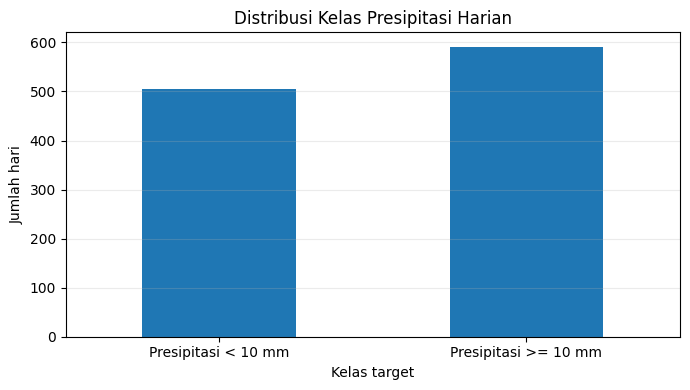

In [5]:
THRESHOLD_MM = 10.0

df["target"] = (df["precipitation_sum"] >= THRESHOLD_MM).astype("int8")
df["target_label"] = np.where(
    df["target"] == 1,
    "Presipitasi >= 10 mm",
    "Presipitasi < 10 mm"
)

counts = df["target_label"].value_counts().reindex(
    ["Presipitasi < 10 mm", "Presipitasi >= 10 mm"], fill_value=0
)
percentages = (counts / counts.sum() * 100).round(2)
balance = pd.DataFrame({"jumlah_hari": counts, "persentase": percentages})
display(balance)

ax = counts.plot(kind="bar", figsize=(7, 4), rot=0)
ax.set_title("Distribusi Kelas Presipitasi Harian")
ax.set_xlabel("Kelas target")
ax.set_ylabel("Jumlah hari")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "distribusi_target.png", dpi=200, bbox_inches="tight")
plt.show()

## 5. Tentukan fitur X dan target y

In [6]:
# Lima fitur meteorologis. Kedua variabel presipitasi tidak dimasukkan ke X
# supaya model tidak mendapatkan variabel yang membentuk label target.
feature_cols = [
    "temperature_2m_mean",
    "relative_humidity_2m_mean",
    "cloud_cover_mean",
    "pressure_msl_mean",
    "wind_speed_10m_mean",
]

X = df[feature_cols].copy()
y = df["target"].copy()

print("Ukuran X:", X.shape)
print("Ukuran y:", y.shape)
print("Kelas y:")
display(y.value_counts().sort_index().rename(index={0: "<10 mm", 1: ">=10 mm"}).to_frame("jumlah"))

# Simpan data hasil penyiapan untuk audit dan reproduksibilitas.
model_ready = df[["date", *feature_cols, "precipitation_sum", "rain_sum", "target", "target_label"]].copy()
model_ready.to_csv(PROCESSED_DIR / "medan_daily_classification_ready.csv", index=False)
print("Data siap model disimpan ke:", PROCESSED_DIR / "medan_daily_classification_ready.csv")

Ukuran X: (1096, 5)
Ukuran y: (1096,)
Kelas y:


,jumlah
target,
<10 mm,505
>=10 mm,591


Data siap model disimpan ke: E:\SEMESTER 5 ILMU KOMPUTER USU\Kecerdasan Buatan\TUGAS prof Poltak\Tugas Pertemuan 9\data\processed\medan_daily_classification_ready.csv


## 6. Siapkan KNN dan Decision Tree

- **KNN:** `StandardScaler` diperlukan karena KNN menentukan tetangga berdasarkan jarak, sementara fitur memiliki satuan/skala berbeda.
- **Decision Tree:** scaling tidak wajib. Kedalaman pohon dibatasi sebagai konfigurasi awal untuk mengurangi risiko pohon terlalu kompleks.
- `SimpleImputer` diletakkan dalam pipeline supaya, apabila ada nilai kosong, median dihitung hanya dari data pelatihan dalam setiap fold. Pipeline juga memastikan scaler KNN tidak di-fit menggunakan keseluruhan data sebelum cross-validation.

Parameter `n_neighbors=5` dan `max_depth=5` adalah konfigurasi awal untuk tugas ini, **bukan klaim sebagai parameter optimal**.

In [7]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

models = {
    "KNN": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", KNeighborsClassifier(n_neighbors=5)),
    ]),
    "Decision Tree": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("classifier", DecisionTreeClassifier(
            max_depth=5,
            min_samples_leaf=5,
            random_state=42
        )),
    ]),
}

print("Validasi: StratifiedKFold, 5 fold, shuffle=True, random_state=42")
print("Jumlah sampel per kelas:")
print(y.value_counts().sort_index())

Validasi: StratifiedKFold, 5 fold, shuffle=True, random_state=42
Jumlah sampel per kelas:
target
0    505
1    591
Name: count, dtype: int64


## 7. Jalankan 5-fold cross-validation dan rangkum metrik.

In [8]:
scoring = {
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced_accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "f1_macro": "f1_macro",
}

rows = []
fold_rows = []
for model_name, estimator in models.items():
    scores = cross_validate(
        estimator,
        X,
        y,
        cv=cv,
        scoring=scoring,
        return_train_score=False,
        n_jobs=-1,
    )

    row = {"model": model_name}
    for metric in scoring:
        values = scores[f"test_{metric}"]
        row[f"{metric}_mean"] = values.mean()
        row[f"{metric}_std"] = values.std(ddof=1)
        for fold_no, value in enumerate(values, start=1):
            fold_rows.append({
                "model": model_name,
                "fold": fold_no,
                "metric": metric,
                "score": value,
            })
    rows.append(row)

summary = pd.DataFrame(rows).sort_values(
    "f1_macro_mean", ascending=False
).reset_index(drop=True)
fold_results = pd.DataFrame(fold_rows)

display(summary.round(3))

summary.to_csv(TABLES_DIR / "knn_vs_decision_tree_cv_summary.csv", index=False)
fold_results.to_csv(TABLES_DIR / "cv_scores_per_fold.csv", index=False)
print("Ringkasan disimpan ke:", TABLES_DIR / "knn_vs_decision_tree_cv_summary.csv")
print("Skor tiap fold disimpan ke:", TABLES_DIR / "cv_scores_per_fold.csv")

,model,accuracy_mean,accuracy_std,balanced_accuracy_mean,balanced_accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,f1_macro_mean,f1_macro_std
0,Decision Tree,0.728,0.026,0.721,0.025,0.723,0.023,0.805,0.061,0.761,0.029,0.722,0.026
1,KNN,0.724,0.021,0.720,0.022,0.734,0.023,0.765,0.032,0.749,0.020,0.721,0.022


Ringkasan disimpan ke: E:\SEMESTER 5 ILMU KOMPUTER USU\Kecerdasan Buatan\TUGAS prof Poltak\Tugas Pertemuan 9\reports\tables\knn_vs_decision_tree_cv_summary.csv
Skor tiap fold disimpan ke: E:\SEMESTER 5 ILMU KOMPUTER USU\Kecerdasan Buatan\TUGAS prof Poltak\Tugas Pertemuan 9\reports\tables\cv_scores_per_fold.csv


## 8. Confusion matrix dan classification report

`precision`, `recall`, dan `f1` default di bawah merujuk ke kelas positif `1`, yakni hari dengan presipitasi ≥10 mm. `macro F1` menghitung F1 masing-masing kelas lalu meratakannya, sehingga kedua kelas mendapat bobot yang sama.

Hasil ini adalah prediksi out-of-fold: setiap baris diprediksi oleh model yang tidak dilatih menggunakan baris tersebut.


===== KNN =====
                      precision    recall  f1-score   support

 Presipitasi < 10 mm      0.710     0.675     0.692       505
Presipitasi >= 10 mm      0.734     0.765     0.749       591

            accuracy                          0.724      1096
           macro avg      0.722     0.720     0.721      1096
        weighted avg      0.723     0.724     0.723      1096



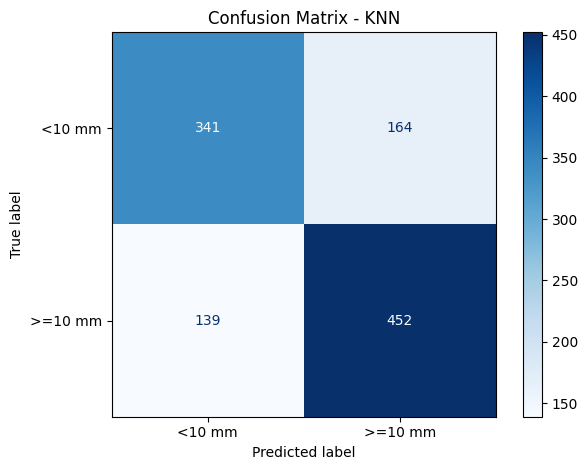

Accuracy OOF: 0.7235
Balanced accuracy OOF: 0.72
Precision kelas >=10 mm: 0.7338
Recall kelas >=10 mm: 0.7648
F1 kelas >=10 mm: 0.749
Macro F1 OOF: 0.7207

===== Decision Tree =====
                      precision    recall  f1-score   support

 Presipitasi < 10 mm      0.737     0.638     0.684       505
Presipitasi >= 10 mm      0.722     0.805     0.762       591

            accuracy                          0.728      1096
           macro avg      0.730     0.722     0.723      1096
        weighted avg      0.729     0.728     0.726      1096



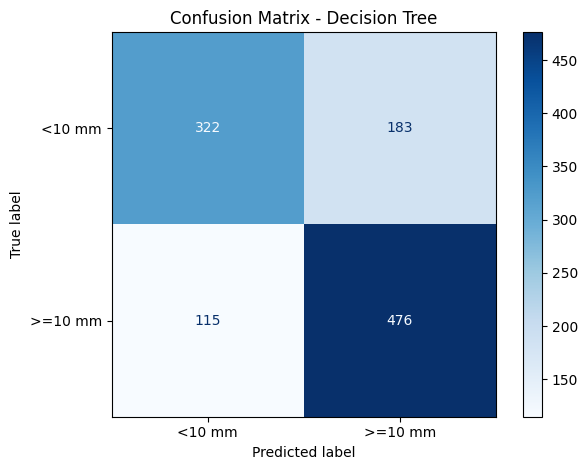

Accuracy OOF: 0.7281
Balanced accuracy OOF: 0.7215
Precision kelas >=10 mm: 0.7223
Recall kelas >=10 mm: 0.8054
F1 kelas >=10 mm: 0.7616
Macro F1 OOF: 0.7226


In [9]:
oof_predictions = {}

for model_name, estimator in models.items():
    y_pred = cross_val_predict(estimator, X, y, cv=cv, n_jobs=-1)
    oof_predictions[model_name] = y_pred

    print(f"\n===== {model_name} =====")
    print(classification_report(
        y,
        y_pred,
        labels=[0, 1],
        target_names=["Presipitasi < 10 mm", "Presipitasi >= 10 mm"],
        digits=3,
        zero_division=0,
    ))

    disp = ConfusionMatrixDisplay.from_predictions(
        y,
        y_pred,
        labels=[0, 1],
        display_labels=["<10 mm", ">=10 mm"],
        values_format="d",
        cmap="Blues",
    )
    disp.ax_.set_title(f"Confusion Matrix - {model_name}")
    plt.tight_layout()
    safe_name = model_name.lower().replace(" ", "_")
    plt.savefig(FIGURES_DIR / f"confusion_matrix_{safe_name}.png", dpi=200, bbox_inches="tight")
    plt.show()

    print("Accuracy OOF:", round(accuracy_score(y, y_pred), 4))
    print("Balanced accuracy OOF:", round(balanced_accuracy_score(y, y_pred), 4))
    print("Precision kelas >=10 mm:", round(precision_score(y, y_pred, zero_division=0), 4))
    print("Recall kelas >=10 mm:", round(recall_score(y, y_pred, zero_division=0), 4))
    print("F1 kelas >=10 mm:", round(f1_score(y, y_pred, zero_division=0), 4))
    print("Macro F1 OOF:", round(f1_score(y, y_pred, average="macro", zero_division=0), 4))

## 9. Grafik perbandingan Macro F1

Gunakan macro F1 sebagai salah satu metrik utama karena memberi bobot sama pada dua kelas. Jangan menentukan model terbaik hanya dari accuracy; baca juga precision, recall, balanced accuracy, variasi skor antarfold, dan confusion matrix.

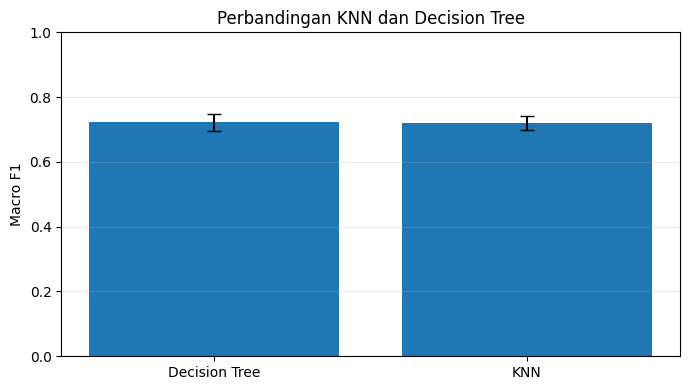

In [10]:
metric = "f1_macro"
plot_df = summary.set_index("model")

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(
    plot_df.index,
    plot_df[f"{metric}_mean"],
    yerr=plot_df[f"{metric}_std"],
    capsize=5,
)
ax.set_ylim(0, 1)
ax.set_ylabel("Macro F1")
ax.set_title("Perbandingan KNN dan Decision Tree")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "perbandingan_macro_f1.png", dpi=200, bbox_inches="tight")
plt.show()